In [85]:
#### basic chatbot
# graph api
from dotenv import load_dotenv
import os

load_dotenv()


groq_api = os.getenv("GROQ_API_KEY")
os.environ["Tavily_api"] = os.getenv("TAVILY_API_KEY")



In [73]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import add_messages, StateGraph, START, END

In [74]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

# Build the graph
graph = StateGraph(State)


In [75]:
graph

In [76]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage

llm = init_chat_model(
    model="llama-3.3-70b-versatile", # A valid Groq model
    model_provider="groq",           # Explicitly set the provider to Groq
    api_key=groq_api                 # Your Groq API key
)

llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.4.8', 'langchain': '1.3.10'}}, output_version=None, profile={'name': 'Llama 3.3 70B Versatile', 'release_date': '2024-12-06', 'last_updated': '2024-12-06', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 32768, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002241CC968D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002241CEC97C0>, model_name='llama-3.3-70b-versatile', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None)

In [77]:
# State
class State(TypedDict):
    messages: Annotated[list, add_messages]


In [78]:
# Node
def chatbot(state: State) -> State:
    # If you need the last message:
    last_message = state["messages"][-1].content
    
    # Or just pass the whole message history to the LLM:
    response = llm.invoke(state["messages"])
    
    return {"messages": [response]}

In [79]:
graph=StateGraph(State, start=START, end=END)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)
model=graph.compile()

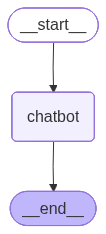

In [80]:
model

In [81]:

# Run
response = model.invoke({"messages": [HumanMessage(content="hii")]})
print(response["messages"][-1].content)

It's nice to meet you. Is there something I can help you with or would you like to chat?


In [82]:
model.invoke({"messages":"hii"})

{'messages': [HumanMessage(content='hii', additional_kwargs={}, response_metadata={}, id='764ed0d6-37c5-4a3b-b995-1b9db78ea7bb'),
  AIMessage(content='Hello. How can I assist you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 37, 'total_tokens': 47, 'completion_time': 0.021880001, 'completion_tokens_details': None, 'prompt_time': 0.001178741, 'prompt_tokens_details': None, 'queue_time': 0.055864338, 'total_time': 0.023058742}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f0574-3a1f-7471-8cf8-3e7f8980694a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 37, 'output_tokens': 10, 'total_tokens': 47})]}

#### Chatbot+tools

In [84]:
from langchain_tavily import TavilySearch

# Instantiate the search tool with configuration parameters
tool = TavilySearch(
    max_results=3 ,
    topic="general",
    # Includes a short parsed text summary
)

# Invoke the tool directly
response = tool.invoke({"query": "What are the latest breakthroughs in fusion energy?"})
print(response)


{'query': 'What are the latest breakthroughs in fusion energy?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.popularmechanics.com/science/energy/a70627756/tokamak-fusion-breakthroughs', 'title': "Fusion Energy Is Finally Advancing. Here's What Changed.", 'content': 'Breakthrough tokamak plasma performance and tech innovations are driving fusion energy toward reality. See the latest scientific progress.', 'score': 0.8170061, 'raw_content': None}, {'url': 'https://www.catf.us/2025/12/fusion-energy-evolving-technology-landscape-western-states', 'title': 'Fusion energy: The evolving technology landscape in Western states', 'content': 'Recent scientific breakthroughs and industrial advancements have positioned fusion energy as a promising solution to meet clean firm energy', 'score': 0.68064564, 'raw_content': None}, {'url': 'https://www.fusionindustryassociation.org/news/fusion-in-the-news', 'title': 'Fusion in the News', 'content': 'EU gives